## **Mount Drive**

In [1]:
from google.colab import drive
import os
import time

def mount_drive(max_attempts=3):

    # Mount Google Drive with automatic retry.

    for attempt in range(max_attempts):
        try:
            # Unmount Drive if already mounted
            try:
                drive.flush_and_unmount()
            except Exception:
                pass

            drive.mount('/content/drive', force_remount=True)
            time.sleep(5)

            # Verify Drive is accessible
            os.listdir('/content/drive/MyDrive')

            print(f"Drive mounted successfully (attempt {attempt + 1})")
            return True

        except Exception as error:
            print(f"Mount attempt {attempt + 1} failed: {error}")
            time.sleep(10)

    print("Failed to mount Google Drive")
    return False


# Mount Google Drive
mount_drive()

# Project directory
PROJECT = '/content/drive/MyDrive/fake_image_detection'

print("Project directory ready")

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive
Drive mounted successfully (attempt 1)
Project directory ready


## **Install libraries**

In [3]:
# Install external packages
!pip install -q timm
!pip install -q grad-cam

# PyTorch
import torch
import torch.nn as nn
import timm
import torchvision.transforms as transforms
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import (
    Dataset,
    DataLoader,
    Subset,
    WeightedRandomSampler
)

# Import GradCAM required libraries.
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Evaluation metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    f1_score
)
from sklearn.utils.class_weight import compute_class_weight

# Data handling
import numpy as np
import pandas as pd
from PIL import Image

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Utilities
from tqdm import tqdm
import itertools
import os
import random
import shutil
import time

# Configure device
device = torch.device('cuda')

print(f"PyTorch: {torch.__version__} | Device: {device}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 109.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
PyTorch: 2.11.0+cu128 | Device: cuda


## **Define paths**

In [4]:
# Drive directories
DFT_REAL = f'{PROJECT}/data/dft/real'
DFT_FAKE = f'{PROJECT}/data/dft/fake'
SPLIT_DIR = f'{PROJECT}/data/splits'
BALANCED_DIR = f'{PROJECT}/data/balanced'

# Local directories
LOCAL_DFT_REAL = '/content/dft/real'
LOCAL_DFT_FAKE = '/content/dft/fake'

# Model output files
CHECKPOINT = f'{PROJECT}/models/m2_efficientnet_checkpoint.pth'
BEST_MODEL = f'{PROJECT}/models/m2_efficientnet_best.pth'
TRAINING_LOG = f'{PROJECT}/logs/m2_efficientnet_log.txt'
SEARCH_RESULTS_FILE = f'{PROJECT}/logs/m2_hyperparameter_search.csv'
PREDICTIONS_DIR = f'{PROJECT}/predictions'

# Create local directories if they do not exist
os.makedirs(LOCAL_DFT_REAL, exist_ok=True)
os.makedirs(LOCAL_DFT_FAKE, exist_ok=True)
os.makedirs(PREDICTIONS_DIR, exist_ok=True)

print("Paths defined")

Paths defined


## **Copy DFT maps to local disk**

In [5]:
# Copy DFT spectrograms to local storage

def copy_in_batches(src, dst, label, batch_size=500):
    """
    Copy files from Drive to local storage in batches.

    Existing files are skipped, allowing interrupted copies
    to resume safely.

    Args:
        src (str): Source directory.
        dst (str): Destination directory.
        label (str): Dataset label.
        batch_size (int): Number of files to copy per batch.
    """
    if not os.path.exists(src):
        print(f"{label}: source folder not found")
        return

    try:
        all_files = os.listdir(src)

    except OSError:
        print(f"{label}: unable to access source folder")
        return

    local_files = set(os.listdir(dst))

    files_to_copy = [
        filename
        for filename in all_files
        if filename not in local_files
    ]

    print(
        f"\n{label}: "
        f"{len(all_files)} on Drive | "
        f"{len(local_files)} local | "
        f"{len(files_to_copy)} to copy"
    )

    if not files_to_copy:
        print(f"{label}: all files already copied")
        return

    copied = 0

    batches = [
        files_to_copy[i:i + batch_size]
        for i in range(0, len(files_to_copy), batch_size)
    ]

    for batch_number, batch in enumerate(batches, start=1):

        print(
            f"Batch {batch_number}/{len(batches)}...",
            end=" ",
            flush=True
        )

        for filename in batch:
            try:
                shutil.copy(
                    os.path.join(src, filename),
                    os.path.join(dst, filename)
                )
                copied += 1

            except Exception:
                pass

        print("Done")

        time.sleep(1)

    print(
        f"{label} complete: "
        f"{copied} copied | "
        f"{len(os.listdir(dst))} files available locally"
    )

# Copy DFT spectrograms
copy_in_batches(DFT_REAL, LOCAL_DFT_REAL, "DFT real")
copy_in_batches(DFT_FAKE, LOCAL_DFT_FAKE, "DFT fake")

print(f"\nLocal DFT real: {len(os.listdir(LOCAL_DFT_REAL))}")
print(f"Local DFT fake: {len(os.listdir(LOCAL_DFT_FAKE))}")


DFT real: 2064 on Drive | 0 local | 2064 to copy
Batch 1/5... Done
Batch 2/5... Done
Batch 3/5... Done
Batch 4/5... Done
Batch 5/5... Done
DFT real complete: 2064 copied | 2064 files available locally

DFT fake: 2064 on Drive | 0 local | 2064 to copy
Batch 1/5... Done
Batch 2/5... Done
Batch 3/5... Done
Batch 4/5... Done
Batch 5/5... Done
DFT fake complete: 2064 copied | 2064 files available locally

Local DFT real: 2064
Local DFT fake: 2064


## **Dataset with balanced split loading**

In [6]:
class DFTDataset(Dataset):
    def __init__(
        self,
        real_dir,
        fake_dir,
        real_files,
        fake_files,
        transform=None
    ):
        """
        Load DFT spectrograms using precomputed balanced file lists.

        Original image filenames are converted to their corresponding
        DFT spectrogram filenames before loading.

        Args:
            real_dir (str): Directory containing real DFT spectrograms.
            fake_dir (str): Directory containing fake DFT spectrograms.
            real_files (list): Balanced list of real image filenames.
            fake_files (list): Balanced list of fake image filenames.
            transform: Torchvision transform pipeline.
        """
        self.transform = transform
        self.samples = []

        # Add real DFT spectrograms
        for filename in real_files:
            dft_name = (
                filename.replace('.jpg', '_dft.jpg')
                        .replace('.png', '_dft.png')
            )

            path = os.path.join(real_dir, dft_name)

            if os.path.exists(path):
                self.samples.append((path, 0))

        # Add fake DFT spectrograms
        for filename in fake_files:
            dft_name = (
                filename.replace('.jpg', '_dft.jpg')
                        .replace('.png', '_dft.png')
            )

            path = os.path.join(fake_dir, dft_name)

            if os.path.exists(path):
                self.samples.append((path, 1))

        real_count = sum(
            1 for _, label in self.samples
            if label == 0
        )

        fake_count = sum(
            1 for _, label in self.samples
            if label == 1
        )

        print(
            f"DFT dataset: {len(self.samples)} images "
            f"({real_count} real | {fake_count} fake)"
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]

        image = Image.open(path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


# Load balanced file lists
with open(f"{BALANCED_DIR}/real_files.txt") as file:
    real_balanced = [
        line.strip()
        for line in file
        if line.strip()
    ]

with open(f"{BALANCED_DIR}/fake_files.txt") as file:
    fake_balanced = [
        line.strip()
        for line in file
        if line.strip()
    ]

print(
    f"Balanced dataset: "
    f"{len(real_balanced)} real | "
    f"{len(fake_balanced)} fake"
)

# Load precomputed dataset splits
train_indices = np.load(
    f"{SPLIT_DIR}/train_indices.npy"
).tolist()

val_indices = np.load(
    f"{SPLIT_DIR}/val_indices.npy"
).tolist()

test_indices = np.load(
    f"{SPLIT_DIR}/test_indices.npy"
).tolist()

# Define image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Build the complete dataset
full_dataset = DFTDataset(
    LOCAL_DFT_REAL,
    LOCAL_DFT_FAKE,
    real_balanced,
    fake_balanced
)

# Remove indices that exceed the available dataset size
max_index = len(full_dataset.samples) - 1

train_indices = [
    index for index in train_indices
    if index <= max_index
]

val_indices = [
    index for index in val_indices
    if index <= max_index
]

test_indices = [
    index for index in test_indices
    if index <= max_index
]

# Create dataset splits
train_data = Subset(full_dataset, train_indices)
val_data = Subset(full_dataset, val_indices)
test_data = Subset(full_dataset, test_indices)

# Apply transforms
train_data.dataset.transform = train_transform
val_data.dataset.transform = eval_transform
test_data.dataset.transform = eval_transform

# Compute class weights
labels = [
    sample[1]
    for sample in full_dataset.samples
]

class_weights = compute_class_weight(
    "balanced",
    classes=np.array([0, 1]),
    y=labels
)

weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float
).to(device)

train_labels = [
    full_dataset.samples[index][1]
    for index in train_indices
]

train_sample_weights = [
    class_weights[label]
    for label in train_labels
]

# Create weighted sampler
sampler = WeightedRandomSampler(
    weights=train_sample_weights,
    num_samples=len(train_sample_weights),
    replacement=True
)

print("\nDFT dataset ready")
print(f"Train: {len(train_data)}")
print(f"Validation: {len(val_data)}")
print(f"Test: {len(test_data)}")

Balanced dataset: 2064 real | 2064 fake
DFT dataset: 4128 images (2064 real | 2064 fake)

DFT dataset ready
Train: 2889
Validation: 619
Test: 620


## **EfficientNet-B0 model builder**

In [7]:
def build_efficientnet(dropout=0.3, num_classes=2):
    """
    Build an EfficientNet-B0 model for binary image classification.

    The pretrained classification layer is replaced with a custom
    classifier head for fine-tuning on the DFT spectrogram dataset.

    Args:
        dropout (float): Dropout rate for the classifier.
        num_classes (int): Number of output classes.

    """
    # Load pretrained EfficientNet-B0 without the default classifier
    model = timm.create_model(
        "efficientnet_b0",
        pretrained=True,
        num_classes=0
    )

    in_features = model.num_features

    # Define the custom classifier
    model.classifier = nn.Sequential(
        nn.Dropout(p=dropout),
        nn.Linear(in_features, 256),
        nn.ReLU(),
        nn.BatchNorm1d(256),
        nn.Dropout(p=round(dropout * 0.6, 2)),
        nn.Linear(256, num_classes)
    )

    return model.to(device)


print("EfficientNet-B0 model builder defined")

EfficientNet-B0 model builder defined


## **Hyperparameter search**

In [8]:
# Define the hyperparameter search space
param_grid = {
    "lr": [1e-3, 1e-4, 1e-5],
    "batch_size": [16, 32],
    "dropout": [0.2, 0.3],
    "weight_decay": [1e-4, 1e-5]
}

# Generate all hyperparameter combinations
keys, values = zip(*param_grid.items())
configs = [
    dict(zip(keys, combination))
    for combination in itertools.product(*values)
]

SEARCH_EPOCHS = 3
search_results = []

print(f"Total configurations: {len(configs)}")
print(f"Epochs per configuration: {SEARCH_EPOCHS}")

criterion_search = nn.CrossEntropyLoss(weight=weights_tensor)

for config_index, config in enumerate(configs, start=1):

    print(f"\nConfiguration {config_index}/{len(configs)}")
    print(config)

    # Create data loaders
    train_loader_search = DataLoader(
        train_data,
        batch_size=config["batch_size"],
        sampler=sampler,
        num_workers=0,
        pin_memory=True
    )

    val_loader_search = DataLoader(
        val_data,
        batch_size=config["batch_size"],
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    # Build model and optimiser
    model_search = build_efficientnet(
        dropout=config["dropout"]
    )

    optimizer_search = Adam(
        model_search.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"]
    )

    # Train the model
    for epoch in range(SEARCH_EPOCHS):

        model_search.train()

        for images, labels in tqdm(
            train_loader_search,
            desc=f"Epoch {epoch + 1}/{SEARCH_EPOCHS}",
            leave=False
        ):
            images = images.to(device)
            labels = labels.to(device)

            optimizer_search.zero_grad()

            outputs = model_search(images)
            loss = criterion_search(outputs, labels)

            loss.backward()
            optimizer_search.step()

    # Evaluate on the validation set
    model_search.eval()

    all_predictions = []
    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in val_loader_search:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_search(images)

            probabilities = torch.softmax(outputs, dim=1)[:, 1]
            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

    validation_accuracy = (100 * sum(
            prediction == label
            for prediction, label in zip(
                all_predictions,
                all_labels
            )
        )
        / len(all_labels)
    )

    validation_auc = roc_auc_score(
        all_labels,
        all_probabilities
    )

    validation_f1 = f1_score(
        all_labels,
        all_predictions,
        average="weighted"
    )

    print(
        f"Validation Accuracy: {validation_accuracy:.2f}% | "
        f"AUC: {validation_auc:.4f} | "
        f"F1: {validation_f1:.4f}"
    )

    search_results.append({
        **config,
        "val_acc": validation_accuracy,
        "val_auc": validation_auc,
        "val_f1": validation_f1
    })

    del model_search
    del optimizer_search
    torch.cuda.empty_cache()

print("\nHyperparameter search complete")

Total configurations: 24
Epochs per configuration: 3

Configuration 1/24
{'lr': 0.001, 'batch_size': 16, 'dropout': 0.2, 'weight_decay': 0.0001}


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Validation Accuracy: 87.56% | AUC: 0.9360 | F1: 0.8756

Configuration 2/24
{'lr': 0.001, 'batch_size': 16, 'dropout': 0.2, 'weight_decay': 1e-05}


Validation Accuracy: 90.15% | AUC: 0.9604 | F1: 0.9009

Configuration 3/24
{'lr': 0.001, 'batch_size': 16, 'dropout': 0.3, 'weight_decay': 0.0001}


Validation Accuracy: 88.05% | AUC: 0.9525 | F1: 0.8803

Configuration 4/24
{'lr': 0.001, 'batch_size': 16, 'dropout': 0.3, 'weight_decay': 1e-05}


... (17 outputs left out)

Validation Accuracy: 88.69% | AUC: 0.9276 | F1: 0.8861

Configuration 22/24
{'lr': 1e-05, 'batch_size': 32, 'dropout': 0.2, 'weight_decay': 1e-05}


Validation Accuracy: 89.34% | AUC: 0.9182 | F1: 0.8927

Configuration 23/24
{'lr': 1e-05, 'batch_size': 32, 'dropout': 0.3, 'weight_decay': 0.0001}


Validation Accuracy: 89.34% | AUC: 0.9213 | F1: 0.8928

Configuration 24/24
{'lr': 1e-05, 'batch_size': 32, 'dropout': 0.3, 'weight_decay': 1e-05}


Validation Accuracy: 88.69% | AUC: 0.9267 | F1: 0.8860

Hyperparameter search complete


## **Select best configuration**

Hyperparameter search results
     lr  batch_size  dropout  weight_decay   val_acc  val_auc   val_f1
0.00100          32      0.3       0.00010 91.114701 0.960570 0.910598
0.00100          16      0.2       0.00001 90.145396 0.960413 0.900895
0.00100          16      0.3       0.00010 88.045234 0.952532 0.880334
0.00100          32      0.3       0.00001 90.468498 0.950517 0.904580
0.00010          32      0.3       0.00001 90.145396 0.950339 0.901299
0.00010          32      0.3       0.00010 89.014540 0.947500 0.890093
0.00010          16      0.3       0.00001 89.499192 0.947495 0.894827
0.00010          16      0.2       0.00010 87.075929 0.944493 0.870698
0.00010          16      0.3       0.00010 87.399031 0.944159 0.873961
0.00010          32      0.2       0.00010 87.883683 0.941351 0.878751
0.00100          32      0.2       0.00001 84.975767 0.941330 0.849143
0.00001          16      0.2       0.00001 88.529887 0.941132 0.884468
0.00010          16      0.2       0.00001 90.6

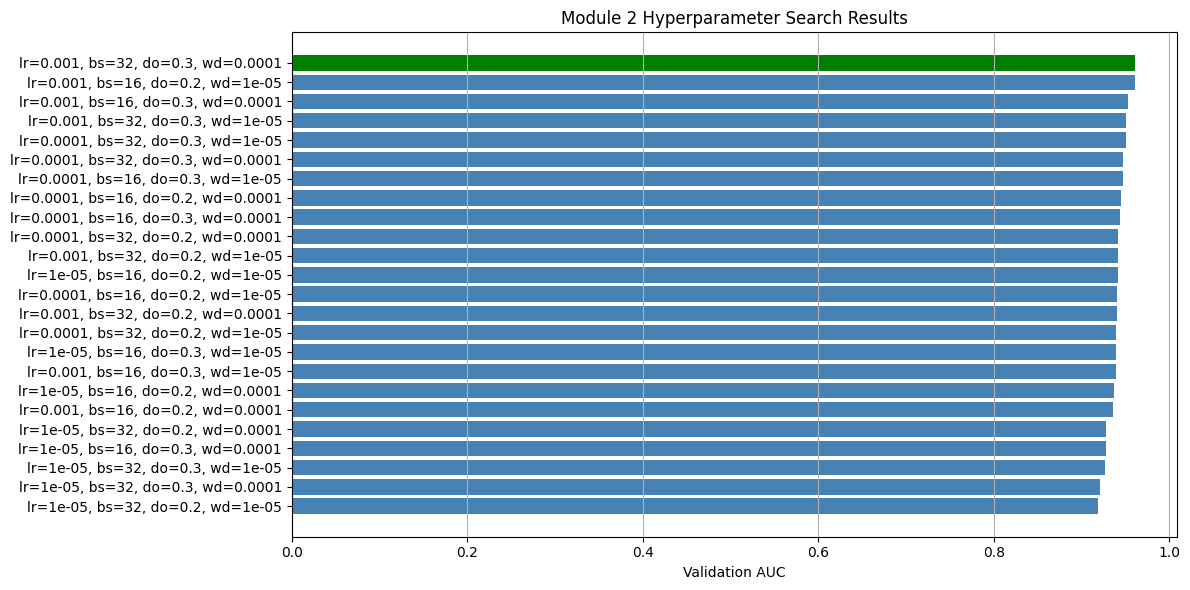

Search results saved


In [9]:
"""Select best hyperparameter configuration"""

# Sort configurations by validation AUC
results_df = (
    pd.DataFrame(search_results)
    .sort_values("val_auc", ascending=False)
    .reset_index(drop=True)
)

best_config = results_df.iloc[0].to_dict()
best_config["batch_size"] = int(best_config["batch_size"])

print("Hyperparameter search results")
print(results_df.to_string(index=False))
print("\nBest configuration")
print(f"Learning rate: {best_config['lr']}")
print(f"Batch size: {best_config['batch_size']}")
print(f"Dropout: {best_config['dropout']}")
print(f"Weight decay: {best_config['weight_decay']}")
print(f"Validation AUC: {best_config['val_auc']:.4f}")

# Save search results
results_df.to_csv(SEARCH_RESULTS_FILE, index=False)

# Plot validation AUC for each configuration
fig, ax = plt.subplots(figsize=(12, 6))

sorted_df = results_df.sort_values("val_auc")

plot_labels = [
    (
        f"lr={row['lr']}, "
        f"bs={int(row['batch_size'])}, "
        f"do={row['dropout']}, "
        f"wd={row['weight_decay']}"
    )
    for _, row in sorted_df.iterrows()
]

bar_colors = ["steelblue"] * len(sorted_df)
bar_colors[-1] = "green"

ax.barh(
    plot_labels,
    sorted_df["val_auc"],
    color=bar_colors
)

ax.set_xlabel("Validation AUC")
ax.set_title("Module 2 Hyperparameter Search Results")
ax.grid(True, axis="x")

plt.tight_layout()
plt.savefig(
    f"{PROJECT}/outputs/m2_hyperparameter_search.png",
    dpi=150
)
plt.show()
print("Search results saved")

## **Build final model**

In [10]:
# Build final model

# Build the model using the best hyperparameters
model = build_efficientnet(
    dropout=best_config["dropout"]
)

# Define the optimiser, learning rate scheduler and loss function
optimizer = Adam(
    model.parameters(),
    lr=best_config["lr"],
    weight_decay=best_config["weight_decay"]
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",
    patience=3,
    factor=0.5
)

criterion = nn.CrossEntropyLoss(
    weight=weights_tensor
)

# Create data loaders
batch_size = best_config["batch_size"]

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    sampler=sampler,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Display the selected configuration
print("Final model configuration")
print(f"Learning rate: {best_config['lr']}")
print(f"Batch size: {batch_size}")
print(f"Dropout: {best_config['dropout']}")
print(f"Weight decay: {best_config['weight_decay']}")

Final model configuration
Learning rate: 0.001
Batch size: 32
Dropout: 0.3
Weight decay: 0.0001


## **Checkpoint functions**

In [11]:
def save_checkpoint(model, optimizer, scheduler,
                    epoch, train_loss, val_loss, val_acc):
    """
    Save the current training state and log the training metrics.

    Args:
        model: Model being trained.
        optimizer: Optimiser used for training.
        scheduler: Learning rate scheduler.
        epoch (int): Current training epoch.
        train_loss (float): Training loss.
        val_loss (float): Validation loss.
        val_acc (float): Validation accuracy.
    """
    torch.save(
        {
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "best_config": best_config,
        },
        CHECKPOINT,
    )

    with open(TRAINING_LOG, "a") as file:
        file.write(
            f"Epoch {epoch + 1:02d} | "
            f"Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}%\n"
        )

    print(f"Checkpoint saved (Epoch {epoch + 1})")


def load_checkpoint(model, optimizer, scheduler):
    """
    Load a previously saved training checkpoint.

    Args:
        model: Model to restore.
        optimizer: Optimiser to restore.
        scheduler: Learning rate scheduler to restore.

    Returns:
        Restored model, optimiser, scheduler and starting epoch.
    """
    if os.path.exists(CHECKPOINT):

        checkpoint = torch.load(
            CHECKPOINT,
            map_location=device
        )

        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        scheduler.load_state_dict(checkpoint["scheduler_state"])

        start_epoch = checkpoint["epoch"] + 1

        print(f"Resumed training from epoch {start_epoch}")

        return model, optimizer, scheduler, start_epoch

    print("No checkpoint found. Starting training from scratch.")

    return model, optimizer, scheduler, 0

print("Checkpoint functions defined")

Checkpoint functions defined


## **Training loop**

In [12]:
# Resume training from the latest checkpoint if available.
model, optimizer, scheduler, start_epoch = load_checkpoint(
    model, optimizer, scheduler
)

# Training configuration.
NUM_EPOCHS = 20
PATIENCE = 5

# Track the best validation performance and training history.
best_val_acc = 0.0
best_val_loss = float('inf')
patience_counter = 0
history = {
    'train_loss': [],
    'val_loss': [],
    'train_acc': [],
    'val_acc': []
}

# Train the model for the specified number of epochs.
for epoch in range(start_epoch, NUM_EPOCHS):

    # Training
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    for imgs, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]"
    ):
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        preds = outputs.argmax(dim=1)
        train_correct += preds.eq(labels).sum().item()
        train_total += labels.size(0)

    # Calculate average training loss and accuracy.
    avg_train_loss = train_loss / len(train_loader)
    train_acc = 100.0 * train_correct / train_total

    # Validation
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        for imgs, labels in tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]"
        ):
            imgs, labels = imgs.to(device), labels.to(device)

            outputs = model(imgs)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            probs = torch.softmax(outputs, dim=1)[:, 1]
            preds = outputs.argmax(dim=1)

            val_correct += preds.eq(labels).sum().item()
            val_total += labels.size(0)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    # Calculate validation metrics.
    avg_val_loss = val_loss / len(val_loader)
    val_acc = 100.0 * val_correct / val_total
    val_f1 = f1_score(all_labels, all_preds, average='weighted')
    val_auc = roc_auc_score(all_labels, all_probs)

    # Update the learning rate scheduler.
    scheduler.step(avg_val_loss)

    # Store training history.
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    # Display epoch results.
    print(f"\nEpoch [{epoch+1}/{NUM_EPOCHS}]")
    print(f"Train Loss: {avg_train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}% | "
        f"F1: {val_f1:.4f} | AUC: {val_auc:.4f}"
    )

    # Save a checkpoint after every epoch.
    save_checkpoint(
        model, optimizer, scheduler, epoch,
        avg_train_loss, avg_val_loss, val_acc
    )

    # Save the best-performing model based on validation accuracy.
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_val_loss = avg_val_loss
        patience_counter = 0
        torch.save(model.state_dict(), BEST_MODEL)
        print(f"Best model saved (Val Acc: {val_acc:.2f}%)")
    else:
        patience_counter += 1
        print(f"No improvement ({patience_counter}/{PATIENCE})")

    # Stop training if validation accuracy has not improved
    # for the specified patience period.
    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch+1}")
        break

print(f"\nTraining complete. Best Validation Accuracy: {best_val_acc:.2f}%")

No checkpoint found. Starting training from scratch.


Epoch 1/20 [Val]: 100%|██████████| 20/20 [00:03<00:00,  5.95it/s]



Epoch [1/20]
Train Loss: 0.3498 | Train Acc: 85.91%
Val Loss: 0.3882 | Val Acc: 90.47% | F1: 0.9042 | AUC: 0.9220
Checkpoint saved (Epoch 1)
Best model saved (Val Acc: 90.47%)


Epoch 2/20 [Val]: 100%|██████████| 20/20 [00:03<00:00,  5.94it/s]



Epoch [2/20]
Train Loss: 0.2204 | Train Acc: 91.38%
Val Loss: 0.2525 | Val Acc: 91.44% | F1: 0.9139 | AUC: 0.9499
Checkpoint saved (Epoch 2)
Best model saved (Val Acc: 91.44%)


Epoch 3/20 [Val]: 100%|██████████| 20/20 [00:03<00:00,  6.03it/s]


... (15 outputs left out)

Epoch 11/20 [Val]: 100%|██████████| 20/20 [00:03<00:00,  5.98it/s]



Epoch [11/20]
Train Loss: 0.0200 | Train Acc: 99.41%
Val Loss: 0.3947 | Val Acc: 91.76% | F1: 0.9174 | AUC: 0.9579
Checkpoint saved (Epoch 11)
No improvement (4/5)


Epoch 12/20 [Val]: 100%|██████████| 20/20 [00:03<00:00,  5.93it/s]



Epoch [12/20]
Train Loss: 0.0222 | Train Acc: 99.27%
Val Loss: 0.3903 | Val Acc: 89.98% | F1: 0.8998 | AUC: 0.9608
Checkpoint saved (Epoch 12)
No improvement (5/5)

Early stopping at epoch 12

Training complete. Best Validation Accuracy: 91.76%


## **Evaluate and save predictions**

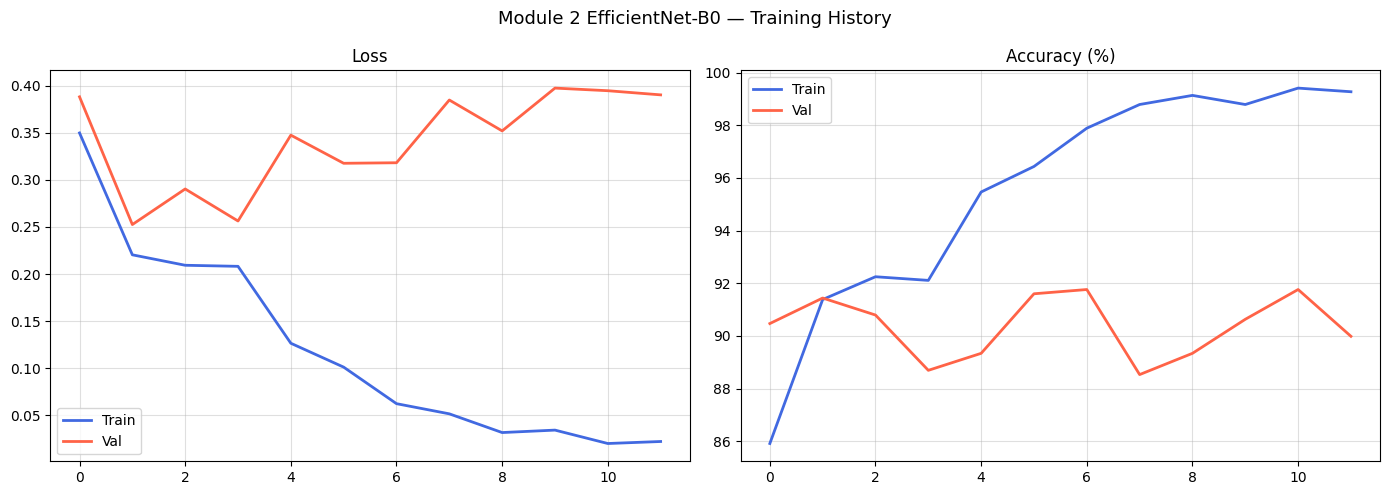

Testing: 100%|██████████| 20/20 [00:03<00:00,  5.47it/s]



MODULE 2 TEST RESULTS
              precision    recall  f1-score   support

        Real       0.94      0.81      0.87       322
        Fake       0.82      0.94      0.88       298

    accuracy                           0.87       620
   macro avg       0.88      0.88      0.87       620
weighted avg       0.88      0.87      0.87       620

AUC-ROC: 0.9388


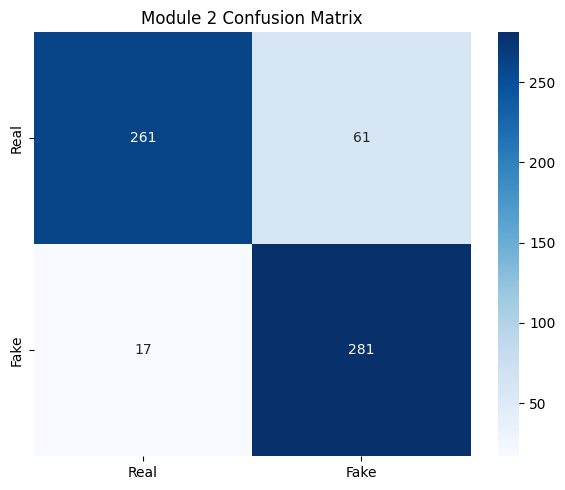


Module 2 predictions saved for fusion.


In [13]:
# Plot the training and validation loss and accuracy curves.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Module 2 EfficientNet-B0 — Training History', fontsize=13)

axes[0].plot(history['train_loss'], label='Train', color='royalblue', lw=2)
axes[0].plot(history['val_loss'], label='Val', color='tomato', lw=2)
axes[0].set_title('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.4)

axes[1].plot(history['train_acc'], label='Train', color='royalblue', lw=2)
axes[1].plot(history['val_acc'], label='Val', color='tomato', lw=2)
axes[1].set_title('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(f'{PROJECT}/outputs/m2_training_curves.png', dpi=150)
plt.show()

# Load the best-performing model for testing.
model.load_state_dict(torch.load(BEST_MODEL, map_location=device))
model.eval()

test_preds, test_labels, test_probs = [], [], []

# Generate predictions on the test dataset.
with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Testing"):
        imgs, labels = imgs.to(device), labels.to(device)

        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        preds = outputs.argmax(dim=1)

        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())
        test_probs.extend(probs.cpu().numpy())

# Display the classification performance.
print("\nMODULE 2 TEST RESULTS")
print(
    classification_report(
        test_labels,
        test_preds,
        target_names=['Real', 'Fake']
    )
)
print(f"AUC-ROC: {roc_auc_score(test_labels, test_probs):.4f}")

# Plot and save the confusion matrix.
cm = confusion_matrix(test_labels, test_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Real', 'Fake'],
    yticklabels=['Real', 'Fake']
)
plt.title('Module 2 Confusion Matrix')
plt.tight_layout()
plt.savefig(f'{PROJECT}/outputs/m2_confusion_matrix.png', dpi=150)
plt.show()

# Save the test predictions for the fusion model.
np.save(f'{PREDICTIONS_DIR}/m2_test_probs.npy', np.array(test_probs))
np.save(f'{PREDICTIONS_DIR}/m2_test_preds.npy', np.array(test_preds))
np.save(f'{PREDICTIONS_DIR}/m2_test_labels.npy', np.array(test_labels))

print("\nModule 2 predictions saved for fusion.")

## **GRAD-CAM**

In [14]:
# Grad-CAM Visualisation (EfficientNet-B0)

# Install the Grad-CAM library.
!pip install -q grad-cam

# Set the model to evaluation mode.
model.eval()

# Select the final convolutional layer of EfficientNet-B0
# as the target layer for Grad-CAM.
target_layers = [model.conv_head]
cam = GradCAM(model=model, target_layers=target_layers)

# Define the preprocessing pipeline for Grad-CAM images.
eval_transform_plain = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Randomly select four real and four fake images.
real_samples = random.sample(
    [s for s in full_dataset.samples if s[1] == 0], 4
)
fake_samples = random.sample(
    [s for s in full_dataset.samples if s[1] == 1], 4
)
all_samples = real_samples + fake_samples

# Create a figure to display the original images and Grad-CAM maps.
fig, axes = plt.subplots(2, 8, figsize=(20, 6))
fig.suptitle(
    "Grad-CAM Visualisation (EfficientNet-B0)\n"
    "Top: DFT Spectrograms | Bottom: Attention Maps",
    fontsize=13
)

# Generate and display Grad-CAM for each selected image.
for idx, (path, label) in enumerate(all_samples):

    image_pil = Image.open(path).convert("RGB")
    image_resized = image_pil.resize((224, 224))
    image_np = np.array(image_resized) / 255.0

    image_tensor = (
        eval_transform_plain(image_pil)
        .unsqueeze(0)
        .to(device)
    )

    grayscale_cam = cam(
        input_tensor=image_tensor,
        targets=[ClassifierOutputTarget(label)]
    )

    cam_image = show_cam_on_image(
        image_np.astype(np.float32),
        grayscale_cam[0],
        use_rgb=True
    )

    label_text = "Real" if label == 0 else "Fake"

    # Display the original image.
    axes[0, idx].imshow(image_resized)
    axes[0, idx].set_title(label_text, fontsize=10)
    axes[0, idx].axis("off")

    # Display the corresponding Grad-CAM heatmap.
    axes[1, idx].imshow(cam_image)
    axes[1, idx].set_title("Grad-CAM", fontsize=9)
    axes[1, idx].axis("off")

# Adjust spacing, save the figure, and display it.
plt.tight_layout()
plt.savefig(f"{PROJECT}/outputs/m2_gradcam.png", dpi=150)
plt.show()

print("Grad-CAM visualisation saved.")

Grad-CAM visualisation saved.
